# CIFAR-10 Image Classification

### Datasets and dataloaders

Dataset: stores samples and labels  
Dataloader: wraps iterable around dataset

In [1]:
#we will use a pre built dataset in this code so thats why i am not importing Dataset
import torch
from torchvision import datasets
from torchvision.transforms import v2
import torch.nn.functional as F

train_data = datasets.CIFAR10(root='data', train=True, download=True, transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]), target_transform=v2.Lambda(lambda y: F.one_hot(torch.tensor(y), num_classes=10).float()))
test_data = datasets.CIFAR10(root='data', train=False, download=True, transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]), target_transform=v2.Lambda(lambda y: F.one_hot(torch.tensor(y), num_classes=10).float()))

/mnt/13198402-5bc3-4484-b2e7-b656d5cdbb5b/Learning_Pytorch/.venv/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


in above cell transform are given which are applied each image before feeding it  
transform are handled by dataset not loader because dataset deals with single image  
  
One more thing:  
transform attribute is for features
target_transform is for labels

Text(0.5, 1.0, 'tensor([0., 0., 0., 0., 0., 0., 1., 0., 0., 0.])')

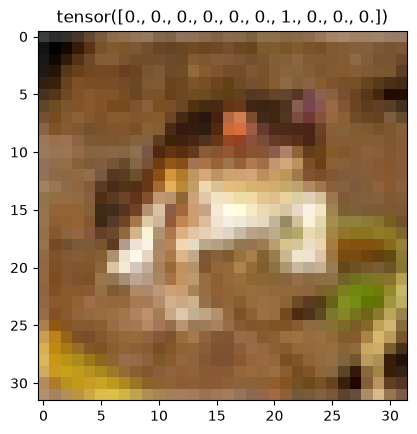

In [2]:
#Visualizing from dataset

import matplotlib.pyplot as plt

img, label = train_data[0]
plt.imshow(img.permute(1, 2, 0))
plt.title(label)

In [3]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Iterating in the dataset  
In below example we are using python iterators  

In [4]:
train_features, train_labels = next(iter(train_dataloader))
print(train_features.shape, train_labels.shape)

torch.Size([64, 3, 32, 32]) torch.Size([64, 10])
